Movie Recommendation System

Problem Statement: 
With thousands of movies available across streaming platforms, users often struggle to discover movies that match their interests and preferences. Traditional movie browsing methods rely heavily on popular or trending titles, which may not necessarily reflect an individual user's taste.
Our project aims to address this challenge by developing a personalized movie recommendation system that analyses historical user ratings and identifies patterns in user preferences.
Using collaborative filtering, the system will identify users with similar rating behavior or movies that receive similar ratings from different users. It will then use these patterns to recommend five movies that a user is likely to enjoy.

Objectives:
    1. Develop a recommendation approach for new users who have little or no rating history.
Success metric: Performance on users with few ratings compared with the pure collaborative model, plus catalog coverage (share of movies ever recommended).
Why it's explainable: "New users still get sensible suggestions, and we don't only recommend blockbusters.

    2. Ensure the recommendation system suggests a variety of movies rather than repeatedly recommending only the most popular titles.
Success metric: Measure catalog coverage and the proportion of recommendations coming from less-popular movies.
Why it's important: Users discover movies beyond mainstream blockbusters, giving lesser-known titles an opportunity to be discovered.

    3. Experiment with different collaborative filtering approaches to identify the model that produces the most accurate predictions.
Success metric: Compare RMSE and MAE across different model configurations and select the best-performing approach.
Why it's important: More accurate predictions help the system recommend movies that better match users' preferences.


Data Exploration and Understanding
    • Obtain and understand the MovieLens dataset.
    • Explore the structure of the dataset and its features.
    • Perform exploratory data analysis (EDA).
    • Analyze rating distributions, popular movies, and user activity.
    • Identify patterns, trends, and potential data quality issues.
    • Present findings to the group.
Deliverable: EDA notebook with visualizations and key findings.

# 01 – Data Exploration & Understanding
**Goal:** understand the MovieLens `ml-latest-small` dataset, run EDA, and surface insights that
shape our three objectives: (1) cold-start users, (2) diversity / catalog coverage, (3) best CF model.

Sections
1. Setup & loading
2. Structure & schema
3. Data quality checks
4. Feature engineering (year, genres)
5. Rating distribution
6. Popular movies
7. User activity
8. Sparsity & long tail (links to Objectives 1 & 2)
9. Genre analysis
10. Temporal trends
11. Tags
12. Key findings

In [1]:
# --- Imports and global plotting style ---
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", 50)

DATA_DIR = "."  # folder that contains the CSVs; change if needed

In [2]:
# --- Load the four MovieLens files ---
ratings = pd.read_csv(f"{DATA_DIR}/ratings.csv")  # userId, movieId, rating, timestamp
movies  = pd.read_csv(f"{DATA_DIR}/movies.csv")   # movieId, title, genres
tags    = pd.read_csv(f"{DATA_DIR}/tags.csv")     # userId, movieId, tag, timestamp
links   = pd.read_csv(f"{DATA_DIR}/links.csv")    # movieId, imdbId, tmdbId

# Convert Unix timestamps (seconds since 1970) into real datetimes
ratings["date"] = pd.to_datetime(ratings["timestamp"], unit="s")
tags["date"]    = pd.to_datetime(tags["timestamp"], unit="s")

for name, df in [("ratings", ratings), ("movies", movies), ("tags", tags), ("links", links)]:
    print(f"{name:8s} -> {df.shape[0]:>7,} rows x {df.shape[1]} cols")

ratings  -> 100,836 rows x 5 cols
movies   ->   9,742 rows x 3 cols
tags     ->   3,683 rows x 5 cols
links    ->   9,742 rows x 3 cols


## 2. Structure & schema
What each table contains and how they join:
- `ratings` – one row per (user, movie) rating, 0.5–5.0 stars. **Core table for collaborative filtering.**
- `movies`  – title (with year) and pipe-separated genres. Used for content features / cold start.
- `tags`    – free-text user tags. Optional content signal.
- `links`   – IDs to IMDb / TMDB. Useful for posters or metadata enrichment.
All tables join on `movieId`; `ratings` and `tags` also share `userId`.

In [3]:
# --- Preview, dtypes and memory for each table ---
for name, df in [("ratings", ratings), ("movies", movies), ("tags", tags), ("links", links)]:
    print(f"\n===== {name.upper()} =====")
    display(df.head(3))
    print(df.dtypes.to_string())
    print(f"Memory: {df.memory_usage(deep=True).sum() / 1024:.1f} KB")

# --- Headline dataset size ---
n_users   = ratings["userId"].nunique()
n_movies_rated = ratings["movieId"].nunique()
n_movies_total = movies["movieId"].nunique()
n_ratings = len(ratings)

print(f"\nUsers: {n_users}")
print(f"Movies in catalog: {n_movies_total} | movies with >=1 rating: {n_movies_rated}")
print(f"Ratings: {n_ratings:,}")
print(f"Date range: {ratings['date'].min().date()} -> {ratings['date'].max().date()}")


===== RATINGS =====


,userId,movieId,rating,timestamp,date
0,1,1,4.0,964982703,2000-07-30 18:45:03
1,1,3,4.0,964981247,2000-07-30 18:20:47
2,1,6,4.0,964982224,2000-07-30 18:37:04


userId                int64
movieId               int64
rating              float64
timestamp             int64
date         datetime64[ns]
Memory: 3939.0 KB

===== MOVIES =====


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance


movieId     int64
title      object
genres     object
Memory: 1565.0 KB

===== TAGS =====


,userId,movieId,tag,timestamp,date
0,2,60756,funny,1445714994,2015-10-24 19:29:54
1,2,60756,Highly quotable,1445714996,2015-10-24 19:29:56
2,2,60756,will ferrell,1445714992,2015-10-24 19:29:52


userId                int64
movieId               int64
tag                  object
timestamp             int64
date         datetime64[ns]
Memory: 356.7 KB

===== LINKS =====


,movieId,imdbId,tmdbId
0,1,114709,862.0
1,2,113497,8844.0
2,3,113228,15602.0


movieId      int64
imdbId       int64
tmdbId     float64
Memory: 228.5 KB

Users: 610
Movies in catalog: 9742 | movies with >=1 rating: 9724
Ratings: 100,836
Date range: 1996-03-29 -> 2018-09-24


## 3. Data quality checks
Checking: missing values, duplicates, invalid rating values, orphan IDs, and title/genre oddities.

In [4]:
# --- Missing values per table ---
for name, df in [("ratings", ratings), ("movies", movies), ("tags", tags), ("links", links)]:
    print(f"\n{name}: missing values")
    print(df.isna().sum()[df.isna().sum() > 0].to_string() or "  none")

# --- Duplicate checks ---
print("\nDuplicate (userId, movieId) ratings:", ratings.duplicated(["userId", "movieId"]).sum())
print("Duplicate movieIds in movies:", movies["movieId"].duplicated().sum())

# --- Are rating values valid? (expected: 0.5 to 5.0 in 0.5 steps) ---
valid = np.arange(0.5, 5.01, 0.5)
print("\nUnique rating values:", sorted(ratings["rating"].unique()))
print("Invalid ratings:", (~ratings["rating"].isin(valid)).sum())

# --- Referential integrity: do all IDs in ratings/tags exist in movies? ---
print("\nRatings with movieId not in movies:", (~ratings["movieId"].isin(movies["movieId"])).sum())
print("Tags with movieId not in movies:",    (~tags["movieId"].isin(movies["movieId"])).sum())

# --- Movies in catalog that nobody rated (only tagged) ---
unrated = set(movies["movieId"]) - set(ratings["movieId"])
print(f"Catalog movies with zero ratings: {len(unrated)}")

# --- Movies with no genre listed ---
no_genre = movies[movies["genres"] == "(no genres listed)"]
print(f"Movies with '(no genres listed)': {len(no_genre)}")

# --- Titles that appear more than once (possible duplicate entries) ---
dup_titles = movies[movies["title"].duplicated(keep=False)].sort_values("title")
print(f"Movies sharing a title with another movieId: {len(dup_titles)}")
display(dup_titles.head(10))

# --- Missing years in titles (checked after extraction below) ---


ratings: missing values
Series([], )

movies: missing values
Series([], )

tags: missing values
Series([], )

links: missing values
tmdbId    8

Duplicate (userId, movieId) ratings: 0
Duplicate movieIds in movies: 0

Unique rating values: [np.float64(0.5), np.float64(1.0), np.float64(1.5), np.float64(2.0), np.float64(2.5), np.float64(3.0), np.float64(3.5), np.float64(4.0), np.float64(4.5), np.float64(5.0)]
Invalid ratings: 0

Ratings with movieId not in movies: 0
Tags with movieId not in movies: 0
Catalog movies with zero ratings: 18
Movies with '(no genres listed)': 34
Movies sharing a title with another movieId: 10


,movieId,title,genres
4169,6003,Confessions of a Dangerous Mind (2002),Comedy|Crime|Drama|Thriller
9106,144606,Confessions of a Dangerous Mind (2002),Comedy|Crime|Drama|Romance|Thriller
650,838,Emma (1996),Comedy|Drama|Romance
5601,26958,Emma (1996),Romance
5854,32600,Eros (2004),Drama
9135,147002,Eros (2004),Drama|Romance
2141,2851,Saturn 3 (1980),Adventure|Sci-Fi|Thriller
9468,168358,Saturn 3 (1980),Sci-Fi|Thriller
5931,34048,War of the Worlds (2005),Action|Adventure|Sci-Fi|Thriller
6932,64997,War of the Worlds (2005),Action|Sci-Fi


## 4. Feature engineering
Extract release year from the title and expand genres into one-hot columns.

In [5]:
# --- Extract release year from titles like "Toy Story (1995)" ---
movies["year"] = movies["title"].str.extract(r"\((\d{4})\)\s*$").astype("float")
movies["clean_title"] = movies["title"].str.replace(r"\s*\(\d{4}\)\s*$", "", regex=True)

print("Movies with no parsable year:", movies["year"].isna().sum())
display(movies[movies["year"].isna()])

# --- Genres: split the pipe-separated string into a list ---
movies["genre_list"] = movies["genres"].str.split("|")

# One-hot encode genres (useful later for content-based / cold-start features)
genre_dummies = movies["genres"].str.get_dummies(sep="|")
movies = pd.concat([movies, genre_dummies], axis=1)

# --- Merge everything into one analysis table ---
df = ratings.merge(movies[["movieId", "title", "year", "genres"]], on="movieId", how="left")
df.head()

Movies with no parsable year: 13


,movieId,title,genres,year,clean_title
6059,40697,Babylon 5,Sci-Fi,NaN,Babylon 5
9031,140956,Ready Player One,Action|Sci-Fi|Thriller,NaN,Ready Player One
9091,143410,Hyena Road,(no genres listed),NaN,Hyena Road
9138,147250,The Adventures of Sherlock Holmes and Doctor W...,(no genres listed),NaN,The Adventures of Sherlock Holmes and Doctor W...
9179,149334,Nocturnal Animals,Drama|Thriller,NaN,Nocturnal Animals
9259,156605,Paterson,(no genres listed),NaN,Paterson
9367,162414,Moonlight,Drama,NaN,Moonlight
9448,167570,The OA,(no genres listed),NaN,The OA
9514,171495,Cosmos,(no genres listed),NaN,Cosmos
9515,171631,Maria Bamford: Old Baby,(no genres listed),NaN,Maria Bamford: Old Baby


,userId,movieId,rating,timestamp,date,title,year,genres
0,1,1,4.0,964982703,2000-07-30 18:45:03,Toy Story (1995),1995.0,Adventure|Animation|Children|Comedy|Fantasy
1,1,3,4.0,964981247,2000-07-30 18:20:47,Grumpier Old Men (1995),1995.0,Comedy|Romance
2,1,6,4.0,964982224,2000-07-30 18:37:04,Heat (1995),1995.0,Action|Crime|Thriller
3,1,47,5.0,964983815,2000-07-30 19:03:35,Seven (a.k.a. Se7en) (1995),1995.0,Mystery|Thriller
4,1,50,5.0,964982931,2000-07-30 18:48:51,"Usual Suspects, The (1995)",1995.0,Crime|Mystery|Thriller


## 5. Rating distribution
Shows how users use the 0.5–5 scale. Skewed ratings affect baseline predictors and RMSE/MAE interpretation.

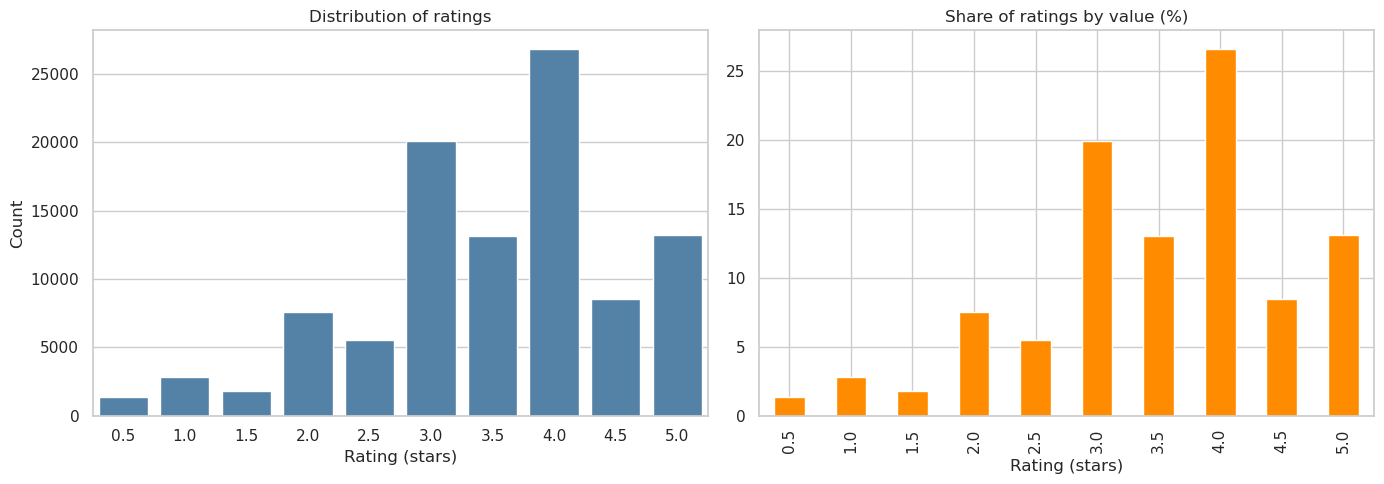

count    100836.000
mean          3.502
std           1.043
min           0.500
25%           3.000
50%           3.500
75%           4.000
max           5.000
Name: rating, dtype: float64

Mean: 3.502 | Median: 3.5 | Mode: 4.0
Skewness: -0.637
% ratings >= 4.0: 48.2%
% whole-star vs half-star: 69.9% / 30.1%


In [6]:
# --- Histogram + summary stats of ratings ---
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=ratings, x="rating", color="steelblue", ax=ax[0])
ax[0].set_title("Distribution of ratings")
ax[0].set_xlabel("Rating (stars)")
ax[0].set_ylabel("Count")

# Share of each rating value
(ratings["rating"].value_counts(normalize=True).sort_index() * 100).plot(
    kind="bar", color="darkorange", ax=ax[1])
ax[1].set_title("Share of ratings by value (%)")
ax[1].set_xlabel("Rating (stars)")
plt.tight_layout()
plt.show()

print(ratings["rating"].describe().round(3))
print(f"\nMean: {ratings['rating'].mean():.3f} | Median: {ratings['rating'].median()} "
      f"| Mode: {ratings['rating'].mode()[0]}")
print(f"Skewness: {ratings['rating'].skew():.3f}")
print(f"% ratings >= 4.0: {(ratings['rating'] >= 4).mean() * 100:.1f}%")
print(f"% whole-star vs half-star: "
      f"{(ratings['rating'] % 1 == 0).mean() * 100:.1f}% / {(ratings['rating'] % 1 != 0).mean() * 100:.1f}%")

## 6. Popular movies
"Popular" can mean most-rated (volume) or highest-rated (quality). A raw average is unreliable for movies with few
ratings, so we also compute a Bayesian (weighted) rating.

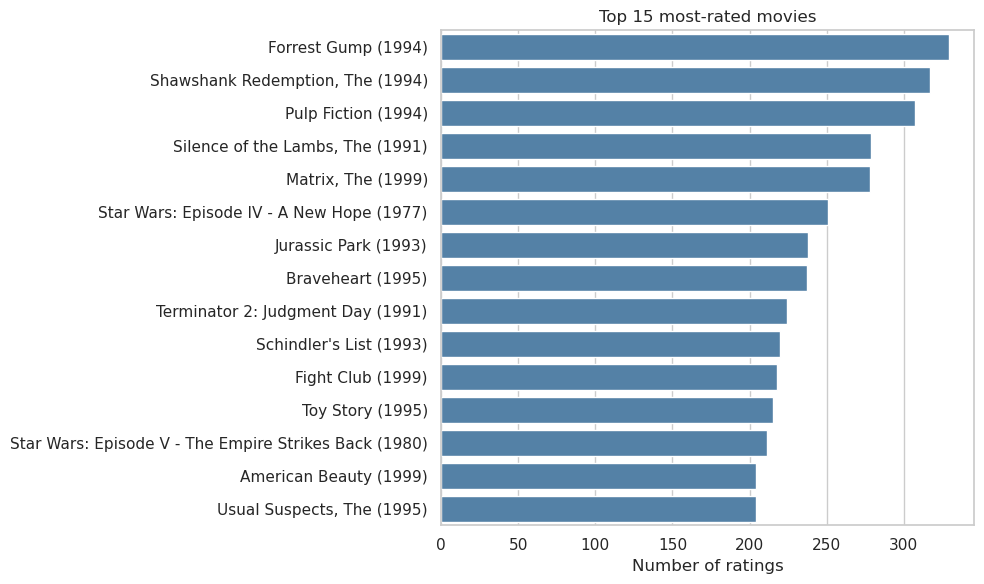

Top 10 by raw mean rating (no minimum votes):


,title,n_ratings,mean_rating
9693,Won't You Be My Neighbor? (2018),1,5.0
4667,Jane Eyre (1944),1,5.0
3802,Rain (2001),1,5.0
7927,Goodbye Charlie (1964),1,5.0
2934,Sorority House Massacre (1986),1,5.0
2933,Slumber Party Massacre III (1990),1,5.0
2932,Slumber Party Massacre II (1987),1,5.0
5015,True Stories (1986),1,5.0
9349,Moonlight,1,5.0
9347,Tom Segura: Mostly Stories (2016),1,5.0



Global mean C = 3.502, threshold m = 12 ratings
Top 10 by weighted rating:


,title,n_ratings,mean_rating,weighted_rating
277,"Shawshank Redemption, The (1994)",317,4.429022,4.395194
659,"Godfather, The (1972)",192,4.289062,4.242739
2224,Fight Club (1999),218,4.272936,4.232690
224,Star Wars: Episode IV - A New Hope (1977),251,4.231076,4.197790
46,"Usual Suspects, The (1995)",204,4.237745,4.196846
921,"Godfather: Part II, The (1974)",129,4.259690,4.195168
461,Schindler's List (1993),220,4.225000,4.187581
913,Goodfellas (1990),126,4.250000,4.184918
602,Dr. Strangelove or: How I Learned to Stop Worr...,97,4.268041,4.183658
6693,"Dark Knight, The (2008)",149,4.238255,4.183346



Spearman correlation (n_ratings vs mean_rating): 0.040


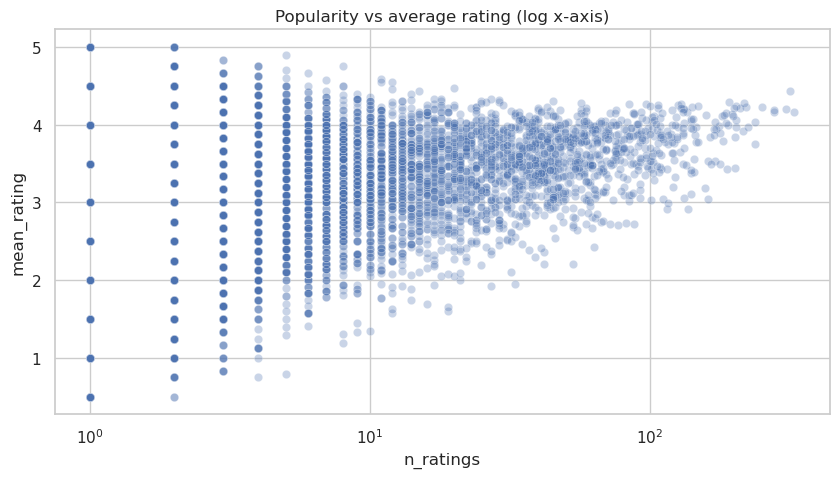

In [7]:
# --- Per-movie stats: number of ratings and mean rating ---
movie_stats = (ratings.groupby("movieId")["rating"]
               .agg(n_ratings="count", mean_rating="mean")
               .reset_index()
               .merge(movies[["movieId", "title", "year", "genres"]], on="movieId"))

# --- Top 15 most-rated movies (popularity by volume) ---
top_count = movie_stats.sort_values("n_ratings", ascending=False).head(15)
plt.figure(figsize=(10, 6))
sns.barplot(data=top_count, y="title", x="n_ratings", color="steelblue")
plt.title("Top 15 most-rated movies")
plt.xlabel("Number of ratings"); plt.ylabel("")
plt.tight_layout(); plt.show()

# --- Highest mean rating WITHOUT a minimum count (shows the small-sample problem) ---
print("Top 10 by raw mean rating (no minimum votes):")
display(movie_stats.sort_values("mean_rating", ascending=False)
        .head(10)[["title", "n_ratings", "mean_rating"]])

# --- Bayesian weighted rating: WR = (v/(v+m))*R + (m/(v+m))*C ---
# v = movie's ratings, R = movie's mean, C = global mean, m = min votes threshold (80th percentile)
C = ratings["rating"].mean()
m = movie_stats["n_ratings"].quantile(0.80)
movie_stats["weighted_rating"] = (
    (movie_stats["n_ratings"] / (movie_stats["n_ratings"] + m)) * movie_stats["mean_rating"]
    + (m / (movie_stats["n_ratings"] + m)) * C
)
print(f"\nGlobal mean C = {C:.3f}, threshold m = {m:.0f} ratings")
print("Top 10 by weighted rating:")
display(movie_stats.sort_values("weighted_rating", ascending=False)
        .head(10)[["title", "n_ratings", "mean_rating", "weighted_rating"]])

# --- Does popularity correlate with quality? ---
corr = movie_stats[["n_ratings", "mean_rating"]].corr(method="spearman").iloc[0, 1]
print(f"\nSpearman correlation (n_ratings vs mean_rating): {corr:.3f}")
sns.scatterplot(data=movie_stats, x="n_ratings", y="mean_rating", alpha=0.3)
plt.xscale("log"); plt.title("Popularity vs average rating (log x-axis)")
plt.show()

## 7. User activity
How much does each user rate, and how do users differ in generosity? Matters for cold start (Objective 1) and
for bias terms in collaborative filtering.

count     610.0
mean      165.3
std       269.5
min        20.0
25%        35.0
50%        70.5
75%       168.0
max      2698.0
Name: n_ratings, dtype: float64

Min ratings per user: 20 (README: users have >= 20)


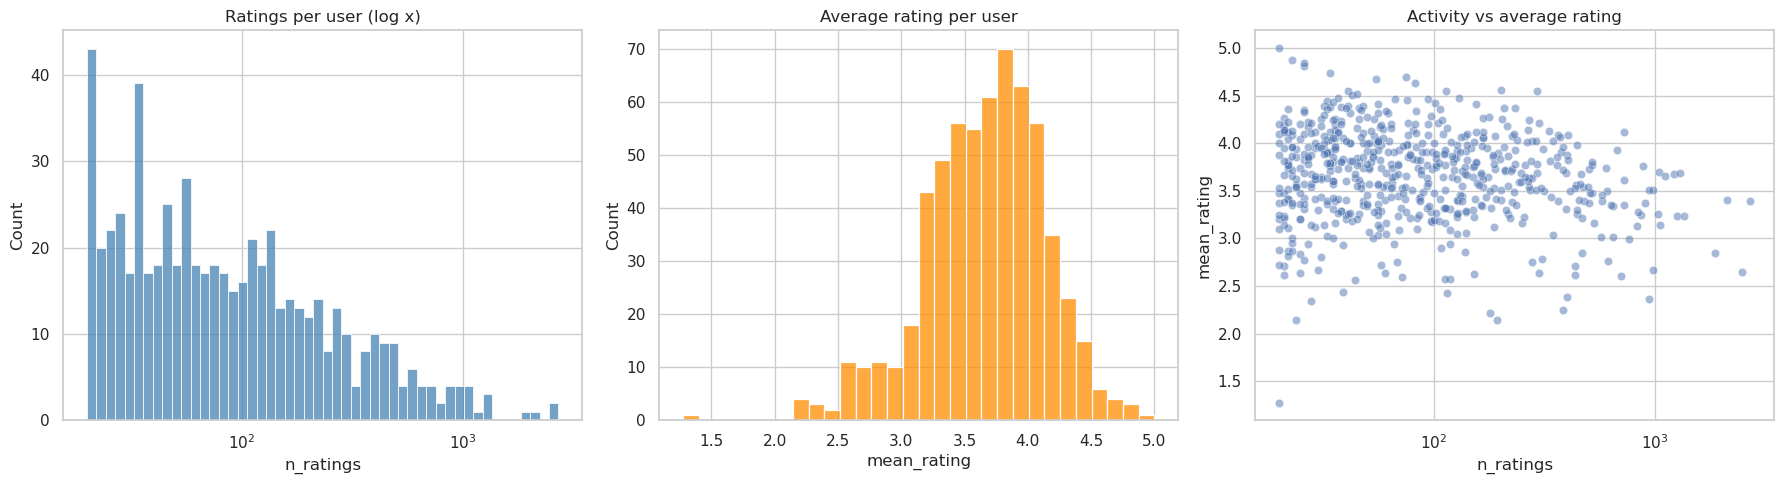

,userId,n_ratings,mean_rating,std_rating
413,414,2698,3.391957,0.933307
598,599,2478,2.642050,0.815300
473,474,2108,3.398956,0.830847
447,448,1864,2.847371,1.029706
273,274,1346,3.235884,0.761703
609,610,1302,3.688556,0.857422
67,68,1260,3.233730,0.896740
379,380,1218,3.673235,0.961010
605,606,1115,3.657399,0.724121
287,288,1055,3.145972,0.866584


Top 10 users account for 16.3% of all ratings

Users per activity band:
activity_band
<=20        14
21-50      218
51-100     133
101-250    141
251-500     61
500+        43


In [8]:
# --- Per-user stats ---
user_stats = (ratings.groupby("userId")["rating"]
              .agg(n_ratings="count", mean_rating="mean", std_rating="std")
              .reset_index())

print(user_stats["n_ratings"].describe().round(1))
print(f"\nMin ratings per user: {user_stats['n_ratings'].min()} (README: users have >= 20)")

fig, ax = plt.subplots(1, 3, figsize=(18, 5))

# Ratings per user (log scale because the distribution is heavily right-skewed)
sns.histplot(user_stats["n_ratings"], bins=50, log_scale=True, ax=ax[0], color="steelblue")
ax[0].set_title("Ratings per user (log x)")

# User average rating: are some users harsh or generous?
sns.histplot(user_stats["mean_rating"], bins=30, ax=ax[1], color="darkorange")
ax[1].set_title("Average rating per user")

# Do heavy raters rate differently?
sns.scatterplot(data=user_stats, x="n_ratings", y="mean_rating", alpha=0.5, ax=ax[2])
ax[2].set_xscale("log"); ax[2].set_title("Activity vs average rating")
plt.tight_layout(); plt.show()

# --- Top 10 most active users and their share of all ratings ---
top_users = user_stats.sort_values("n_ratings", ascending=False).head(10)
display(top_users)
print(f"Top 10 users account for {top_users['n_ratings'].sum() / len(ratings) * 100:.1f}% of all ratings")

# --- Light vs heavy users (useful to define 'few ratings' for the cold-start objective) ---
bins = [0, 20, 50, 100, 250, 500, np.inf]
labels = ["<=20", "21-50", "51-100", "101-250", "251-500", "500+"]
user_stats["activity_band"] = pd.cut(user_stats["n_ratings"], bins=bins, labels=labels)
print("\nUsers per activity band:")
print(user_stats["activity_band"].value_counts().sort_index().to_string())

## 8. Sparsity & the long tail
Collaborative filtering struggles when the user-item matrix is sparse and when most items have few ratings.
This directly motivates **Objective 1 (cold start)** and **Objective 2 (diversity / coverage)**.

Matrix size: 610 x 9724 = 5,931,640 cells
Sparsity: 98.30% empty


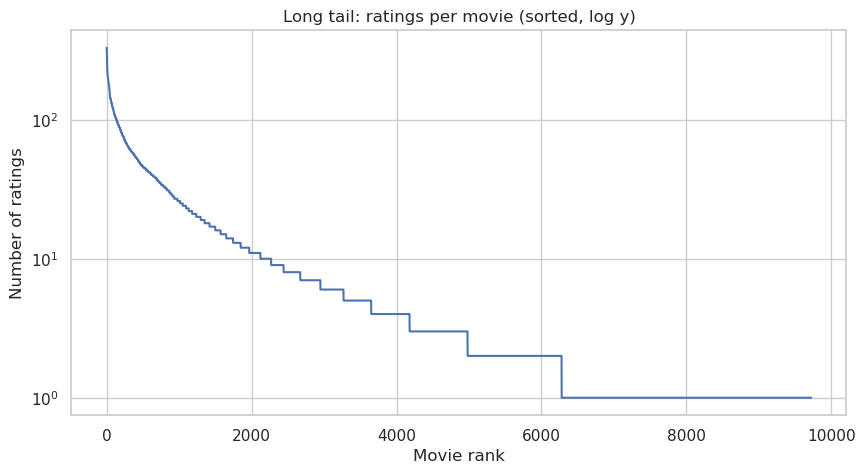

Top    1% of movies (  97) hold 15.7% of ratings
Top    5% of movies ( 486) hold 42.7% of ratings
Top   10% of movies ( 972) hold 60.0% of ratings
Top   20% of movies (1944) hold 77.0% of ratings
Movies with <=  1 ratings:  3446 (35.4%)
Movies with <=  2 ratings:  4744 (48.8%)
Movies with <=  5 ratings:  6456 (66.4%)
Movies with <= 10 ratings:  7603 (78.2%)

Segment sizes:
 segment
tail    7757
head    1967


In [9]:
# --- Sparsity of the user-item matrix ---
possible = n_users * n_movies_rated
sparsity = 1 - len(ratings) / possible
print(f"Matrix size: {n_users} x {n_movies_rated} = {possible:,} cells")
print(f"Sparsity: {sparsity * 100:.2f}% empty")

# --- Long-tail: sorted movie popularity curve ---
sorted_counts = movie_stats["n_ratings"].sort_values(ascending=False).reset_index(drop=True)
plt.figure(figsize=(10, 5))
plt.plot(sorted_counts.values)
plt.yscale("log")
plt.title("Long tail: ratings per movie (sorted, log y)")
plt.xlabel("Movie rank"); plt.ylabel("Number of ratings")
plt.show()

# --- How concentrated are ratings? (cumulative share held by top-k movies) ---
cum_share = sorted_counts.cumsum() / sorted_counts.sum()
for pct in [0.01, 0.05, 0.10, 0.20]:
    k = int(len(sorted_counts) * pct)
    print(f"Top {pct * 100:>4.0f}% of movies ({k:>4}) hold {cum_share.iloc[k - 1] * 100:.1f}% of ratings")

# --- Cold-start items: movies with very few ratings ---
for t in [1, 2, 5, 10]:
    n = (movie_stats["n_ratings"] <= t).sum()
    print(f"Movies with <= {t:>2} ratings: {n:>5} ({n / len(movie_stats) * 100:.1f}%)")

# --- Define popular head vs long tail (reuse later for Objective 2 metrics) ---
# Example rule: 'head' = top 20% of movies by rating count, 'tail' = the rest
threshold = movie_stats["n_ratings"].quantile(0.80)
movie_stats["segment"] = np.where(movie_stats["n_ratings"] >= threshold, "head", "tail")
print("\nSegment sizes:\n", movie_stats["segment"].value_counts().to_string())

## 9. Genre analysis
Which genres are most common, and which are rated higher? Useful for content features in the cold-start approach.

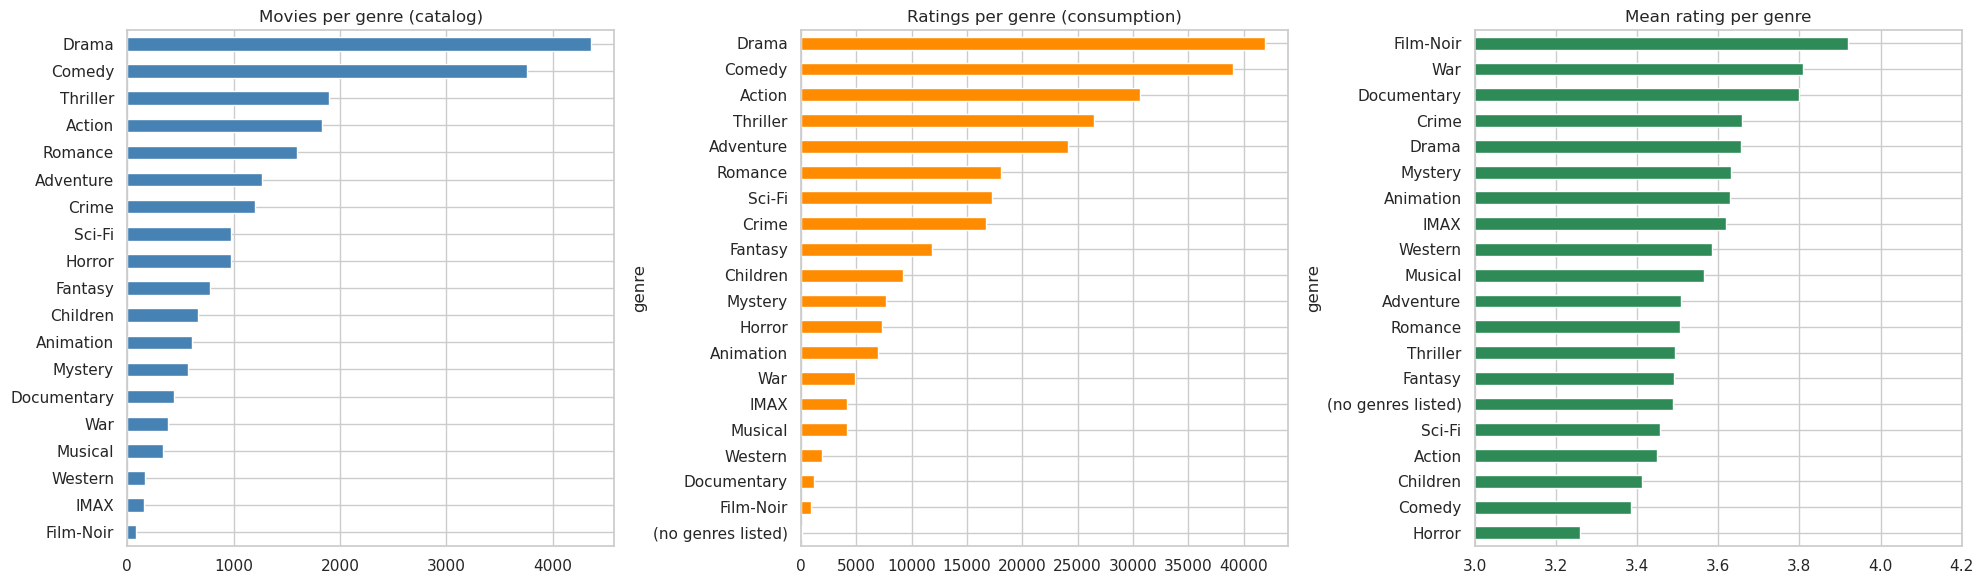

Genres per movie:
 count    9742.00
mean        2.26
std         1.13
min         0.00
25%         1.00
50%         2.00
75%         3.00
max        10.00


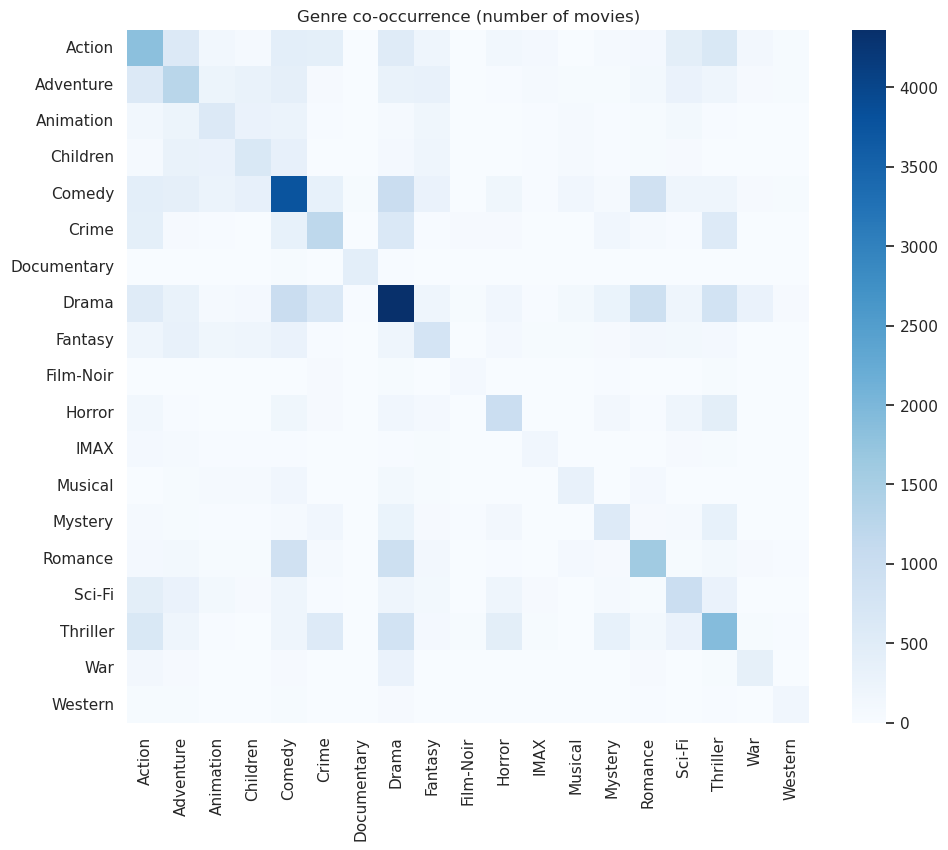

In [10]:
genre_cols = [c for c in genre_dummies.columns if c != "(no genres listed)"]

# --- Number of movies per genre (catalog view) ---
catalog_counts = movies[genre_cols].sum().sort_values(ascending=False)

# --- Number of ratings and mean rating per genre (user view) ---
# Explode genres so each rating row is repeated once per genre of its movie
exploded = df.assign(genre=df["genres"].str.split("|")).explode("genre")
genre_stats = (exploded.groupby("genre")["rating"]
               .agg(n_ratings="count", mean_rating="mean")
               .sort_values("n_ratings", ascending=False))

fig, ax = plt.subplots(1, 3, figsize=(20, 6))
catalog_counts.plot(kind="barh", ax=ax[0], color="steelblue"); ax[0].invert_yaxis()
ax[0].set_title("Movies per genre (catalog)")

genre_stats["n_ratings"].plot(kind="barh", ax=ax[1], color="darkorange"); ax[1].invert_yaxis()
ax[1].set_title("Ratings per genre (consumption)")

genre_stats["mean_rating"].sort_values().plot(kind="barh", ax=ax[2], color="seagreen")
ax[2].set_xlim(3, 4.2); ax[2].set_title("Mean rating per genre")
plt.tight_layout(); plt.show()

# --- Genres per movie ---
print("Genres per movie:\n", movies[genre_cols].sum(axis=1).describe().round(2).to_string())

# --- Genre co-occurrence heatmap (which genres appear together) ---
co = movies[genre_cols].T.dot(movies[genre_cols])
plt.figure(figsize=(11, 9))
sns.heatmap(co, cmap="Blues", annot=False)
plt.title("Genre co-occurrence (number of movies)")
plt.show()

## 10. Temporal trends
Release-year distribution of movies, and how rating activity and average scores changed over time.

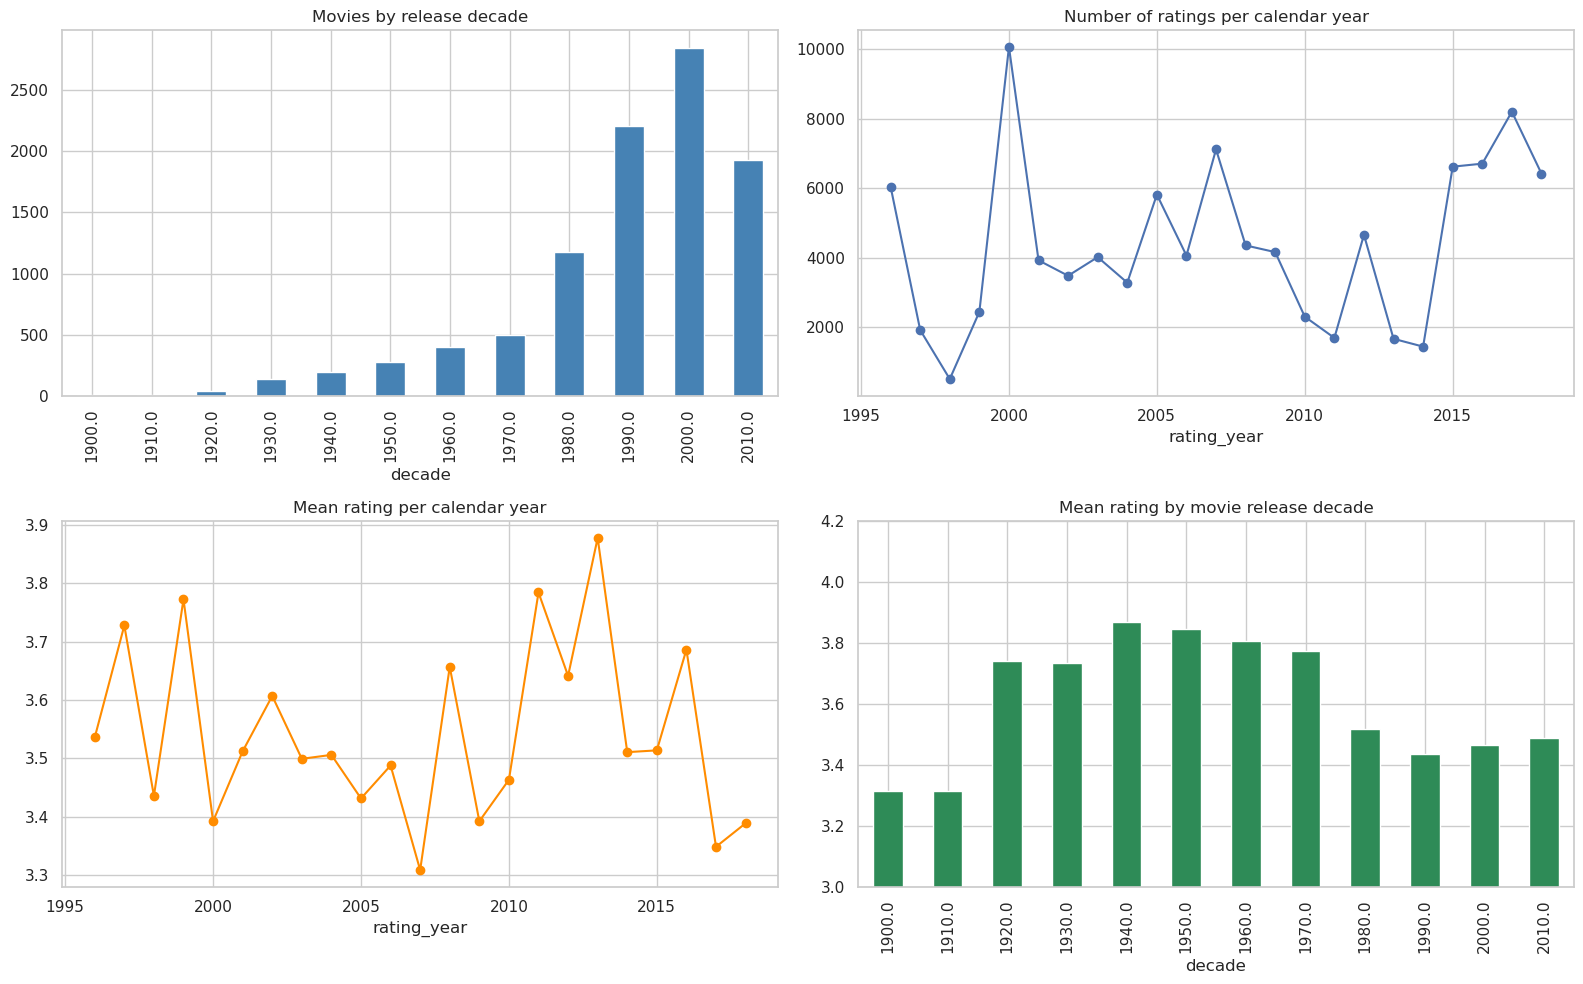

Days between first and last rating per user:
count     610.0
mean      234.1
std       748.8
min         0.0
25%         0.0
50%         0.0
75%        38.0
max      6557.0
Users who rated everything within 1 day: 63.3%


In [11]:
fig, ax = plt.subplots(2, 2, figsize=(16, 10))

# Movies by release decade
movies["decade"] = (movies["year"] // 10 * 10)
movies["decade"].value_counts().sort_index().plot(kind="bar", ax=ax[0, 0], color="steelblue")
ax[0, 0].set_title("Movies by release decade")

# Ratings per year (when users were active)
df["rating_year"] = df["date"].dt.year
df["rating_year"].value_counts().sort_index().plot(ax=ax[0, 1], marker="o")
ax[0, 1].set_title("Number of ratings per calendar year")

# Mean rating per year
df.groupby("rating_year")["rating"].mean().plot(ax=ax[1, 0], marker="o", color="darkorange")
ax[1, 0].set_title("Mean rating per calendar year")

# Do users prefer older or newer films? Mean rating by movie release decade
df["decade"] = df["year"] // 10 * 10
df.groupby("decade")["rating"].mean().plot(kind="bar", ax=ax[1, 1], color="seagreen")
ax[1, 1].set_ylim(3, 4.2); ax[1, 1].set_title("Mean rating by movie release decade")
plt.tight_layout(); plt.show()

# --- Time span of each user's activity (are most users one-session raters?) ---
span = df.groupby("userId")["date"].agg(lambda s: (s.max() - s.min()).days)
print("Days between first and last rating per user:")
print(span.describe().round(1).to_string())
print(f"Users who rated everything within 1 day: {(span <= 1).mean() * 100:.1f}%")

## 11. Tags
Tags are sparse but may provide an extra content signal for cold-start users.

Tag applications: 3,683 | unique tags: 1,589 | users who tagged: 58 | movies tagged: 1572


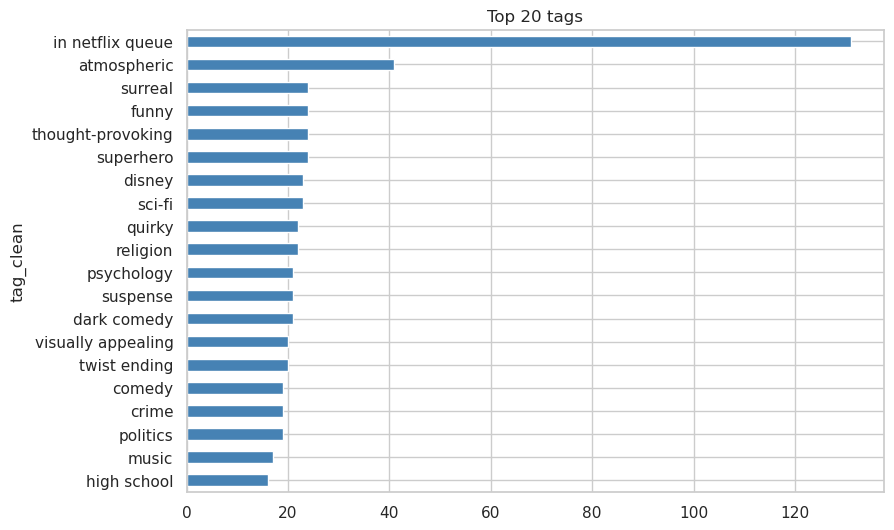

Share of rated movies with >=1 tag: 16.2%

Top 5 taggers' share of all tags: 79.1%


In [12]:
print(f"Tag applications: {len(tags):,} | unique tags: {tags['tag'].nunique():,} "
      f"| users who tagged: {tags['userId'].nunique()} | movies tagged: {tags['movieId'].nunique()}")

# Normalise tags (lowercase/strip) so 'Sci-Fi' and 'sci-fi ' are the same tag
tags["tag_clean"] = tags["tag"].str.lower().str.strip()
top_tags = tags["tag_clean"].value_counts().head(20)

top_tags.sort_values().plot(kind="barh", figsize=(9, 6), color="steelblue")
plt.title("Top 20 tags"); plt.show()

# Tag coverage: what share of rated movies have at least one tag?
tagged_movies = tags["movieId"].nunique()
print(f"Share of rated movies with >=1 tag: {tagged_movies / n_movies_rated * 100:.1f}%")

# Concentration: a few users produce most tags
print("\nTop 5 taggers' share of all tags:",
      f"{tags['userId'].value_counts().head(5).sum() / len(tags) * 100:.1f}%")

## 12. Train/test considerations (preview for modelling)
Checks that affect how we split data later.

In [13]:
# --- Baseline: predict the global mean for everyone. Any model must beat this RMSE. ---
global_mean = ratings["rating"].mean()
baseline_rmse = np.sqrt(((ratings["rating"] - global_mean) ** 2).mean())
baseline_mae  = (ratings["rating"] - global_mean).abs().mean()
print(f"Global-mean baseline -> RMSE: {baseline_rmse:.4f} | MAE: {baseline_mae:.4f}")

# --- Baseline with user & item bias (a simple but strong CF benchmark) ---
user_bias = ratings.groupby("userId")["rating"].mean() - global_mean
item_bias = ratings.groupby("movieId")["rating"].mean() - global_mean
pred = (global_mean
        + ratings["userId"].map(user_bias)
        + ratings["movieId"].map(item_bias)).clip(0.5, 5)
print(f"Bias baseline (in-sample, optimistic) -> RMSE: {np.sqrt(((ratings['rating'] - pred) ** 2).mean()):.4f}")

# --- How many test users/items would be unseen under a random split? ---
# Items with 1 rating cannot appear in both train and test: this is an item cold-start issue
print(f"\nMovies with exactly 1 rating: {(movie_stats['n_ratings'] == 1).sum()}")
print("Recommendation: use a per-user split (hold out ~20% of each user's ratings) so every test user has train history.")

Global-mean baseline -> RMSE: 1.0425 | MAE: 0.8271
Bias baseline (in-sample, optimistic) -> RMSE: 0.8199

Movies with exactly 1 rating: 3446
Recommendation: use a per-user split (hold out ~20% of each user's ratings) so every test user has train history.


In [14]:
# --- Print a findings summary from the actual data so the markdown below can be verified ---
print("KEY FINDINGS (computed)")
print("-" * 50)
print(f"1. Size: {n_ratings:,} ratings, {n_users} users, {n_movies_rated:,} rated movies "
      f"({n_movies_total:,} in catalog).")
print(f"2. Sparsity: {sparsity * 100:.2f}% of the user-item matrix is empty.")
print(f"3. Ratings: mean {ratings['rating'].mean():.2f}, mode {ratings['rating'].mode()[0]}, "
      f"{(ratings['rating'] >= 4).mean() * 100:.0f}% are >= 4 stars (positive skew).")
print(f"4. Users: median {user_stats['n_ratings'].median():.0f} ratings/user, max {user_stats['n_ratings'].max()}.")
print(f"5. Long tail: {(movie_stats['n_ratings'] <= 5).mean() * 100:.0f}% of movies have <= 5 ratings; "
      f"top 20% of movies hold {cum_share.iloc[int(len(sorted_counts) * 0.2) - 1] * 100:.0f}% of ratings.")
print(f"6. Most-rated genre: {genre_stats.index[0]}; best-rated (n>=1000): "
      f"{genre_stats[genre_stats['n_ratings'] >= 1000]['mean_rating'].idxmax()}.")
print(f"7. Baseline RMSE (global mean): {baseline_rmse:.3f}.")
print(f"8. Data quality: {len(unrated)} unrated catalog movies, {len(no_genre)} with no genre, "
      f"{movies['year'].isna().sum()} titles without a year.")

KEY FINDINGS (computed)
--------------------------------------------------
1. Size: 100,836 ratings, 610 users, 9,724 rated movies (9,742 in catalog).
2. Sparsity: 98.30% of the user-item matrix is empty.
3. Ratings: mean 3.50, mode 4.0, 48% are >= 4 stars (positive skew).
4. Users: median 70 ratings/user, max 2698.
5. Long tail: 66% of movies have <= 5 ratings; top 20% of movies hold 77% of ratings.
6. Most-rated genre: Drama; best-rated (n>=1000): War.
7. Baseline RMSE (global mean): 1.043.
8. Data quality: 18 unrated catalog movies, 34 with no genre, 13 titles without a year.
